### 0. 데이터 불러오기

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")

print("Path to dataset files:", path)

c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\82102\.cache\kagglehub\datasets\uciml\default-of-credit-card-clients-dataset\versions\1


In [2]:
import os

# 다운로드된 폴더 안 파일 목록 확인
for f in os.listdir(path):
    print(f)

UCI_Credit_Card.csv


In [3]:
import pandas as pd

file_name = "UCI_Credit_Card.csv"
df = pd.read_csv(os.path.join(path, file_name))

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [4]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='str')

### 1. 전처리

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

##### 1_1. 변수 제외

In [6]:
# ── 1) 제외 대상 변수 ─────────────────────────────────────────────
# - ID: 식별자, 분석 의미 없음
# - PAY_0: 정보 누수 가능성을 고려하여 제외
# - BILL_AMT1, PAY_AMT1: PAY_0과 동일 시점이므로 함께 제외
drop_cols = ['ID', 'PAY_0', 'BILL_AMT1', 'PAY_AMT1']

print("=== 1) 변수 제외 전 shape ===")
print(df.shape)

# ── 2) 변수 제외 ──────────────────────────────────────────────────
df = df.drop(columns=drop_cols)

print("\n=== 2) 변수 제외 후 shape ===")
print(df.shape)
print("남은 컬럼:", df.columns.tolist())

=== 1) 변수 제외 전 shape ===
(30000, 25)

=== 2) 변수 제외 후 shape ===
(30000, 21)
남은 컬럼: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


##### 1_2. Target

=== 1) 클래스 분포 ===


,count,ratio
정상(0),23364,0.779
연체(1),6636,0.221


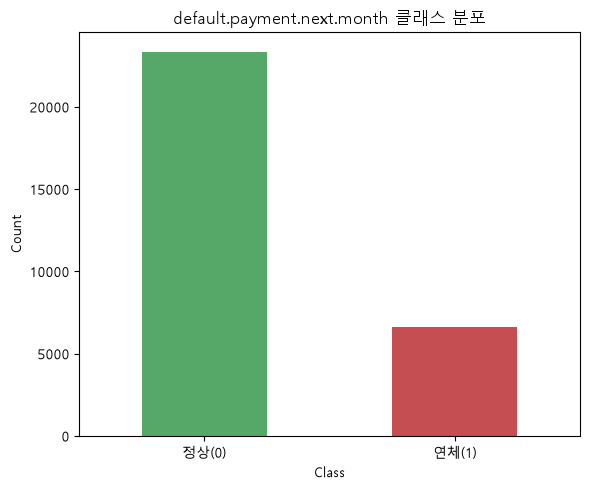

In [7]:
target = 'default.payment.next.month'

# ── 1) 클래스별 빈도 및 비율 집계 ────────────────────────────────
class_dist = df[target].value_counts().sort_index()
class_ratio = df[target].value_counts(normalize=True).sort_index().round(3)

class_summary = pd.DataFrame({'count': class_dist, 'ratio': class_ratio})
class_summary.index = ['정상(0)', '연체(1)']

print("=== 1) 클래스 분포 ===")
display(class_summary)

# ── 2) 클래스 분포 막대그래프 ──────────────────────────────────
plt.figure(figsize=(6, 5))
class_summary['count'].plot(kind='bar', color=['#55A868', '#C44E52'])
plt.title('default.payment.next.month 클래스 분포')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### 1_3. Nomial Feature

분포 확인

In [8]:
# ── 1) 개인 특성 변수 값 분포 (SEX, EDUCATION, MARRIAGE) ──────────
print("=== 1) 개인 특성 변수 값 분포 ===")
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    col_dist = df[col].value_counts().sort_index()
    col_ratio = df[col].value_counts(normalize=True).sort_index().round(3)

    print(f"\n[{col}]")
    display(pd.DataFrame({'count': col_dist, 'ratio': col_ratio}))

# ── 2) 상환 이력 변수 값 분포 (PAY_2 ~ PAY_6) ─────────────────────
pay_cols = ['PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

pay_dist = pd.DataFrame(
    {col: df[col].value_counts().sort_index() for col in pay_cols}
).fillna(0).astype(int)

print("\n=== 2) PAY_2 ~ PAY_6 값 분포 ===")
display(pay_dist)

=== 1) 개인 특성 변수 값 분포 ===

[SEX]


,count,ratio
SEX,,
1,11888,0.396
2,18112,0.604



[EDUCATION]


,count,ratio
EDUCATION,,
0,14,0.000
1,10585,0.353
2,14030,0.468
3,4917,0.164
4,123,0.004
5,280,0.009
6,51,0.002



[MARRIAGE]


,count,ratio
MARRIAGE,,
0,54,0.002
1,13659,0.455
2,15964,0.532
3,323,0.011



=== 2) PAY_2 ~ PAY_6 값 분포 ===


,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,3782,4085,4348,4546,4895
-1,6050,5938,5687,5539,5740
0,15730,15764,16455,16947,16286
1,28,4,2,0,0
2,3927,3819,3159,2626,2766
3,326,240,180,178,184
4,99,76,69,84,49
5,25,21,35,17,13
6,12,23,5,4,19
7,20,27,58,58,46


PAY_k 검증

In [9]:
# ── 1) PAY_k 값별 건수, 연체율, 평균 청구액/납부액, 청구액 0 이하 비율 ──
for k in range(2, 7):
    pay_col = f'PAY_{k}'
    bill_col = f'BILL_AMT{k}'
    payamt_col = f'PAY_AMT{k}'

    pay_check = df.groupby(pay_col).agg(
        count=(target, 'count'),
        default_rate=(target, 'mean'),
        mean_bill=(bill_col, 'mean'),
        mean_payamt=(payamt_col, 'mean'),
        bill_nonpositive_ratio=(bill_col, lambda x: (x <= 0).mean())
    ).round(3)
    pay_check['payamt/bill'] = (pay_check['mean_payamt'] / pay_check['mean_bill']).round(3)

    print(f"\n=== 1) {pay_col} 값별 검증 ({bill_col}, {payamt_col}) ===")
    display(pay_check)


=== 1) PAY_2 값별 검증 (BILL_AMT2, PAY_AMT2) ===


,count,default_rate,mean_bill,mean_payamt,bill_nonpositive_ratio,payamt/bill
PAY_2,,,,,,
-2,3782,0.183,5138.198,6058.831,0.557,1.179
-1,6050,0.160,9351.503,8794.527,0.116,0.940
0,15730,0.159,74629.305,5600.348,0.018,0.075
1,28,0.179,27557.929,31604.071,0.750,1.147
2,3927,0.556,50453.511,3084.184,0.016,0.061
3,326,0.617,47145.028,1106.706,0.000,0.023
4,99,0.505,55722.192,468.515,0.000,0.008
5,25,0.600,76468.960,564.200,0.000,0.007
6,12,0.750,129849.250,189.000,0.000,0.001



=== 1) PAY_3 값별 검증 (BILL_AMT3, PAY_AMT3) ===


,count,default_rate,mean_bill,mean_payamt,bill_nonpositive_ratio,payamt/bill
PAY_3,,,,,,
-2,4085,0.185,4325.256,4394.233,0.615,1.016
-1,5938,0.156,11029.447,7987.432,0.095,0.724
0,15764,0.175,71547.305,5063.506,0.020,0.071
1,4,0.250,118521.000,4727.250,0.000,0.040
2,3819,0.516,47126.797,2946.151,0.033,0.063
3,240,0.575,41628.962,824.929,0.000,0.020
4,76,0.579,62839.105,1042.592,0.000,0.017
5,21,0.571,84724.333,310.857,0.000,0.004
6,23,0.609,92717.696,131.304,0.000,0.001



=== 1) PAY_4 값별 검증 (BILL_AMT4, PAY_AMT4) ===


,count,default_rate,mean_bill,mean_payamt,bill_nonpositive_ratio,payamt/bill
PAY_4,,,,,,
-2,4348,0.193,3354.493,3878.188,0.667,1.156
-1,5687,0.159,10503.225,6996.049,0.102,0.666
0,16455,0.183,64287.720,4827.792,0.018,0.075
1,2,0.500,185766.000,7550.000,0.000,0.041
2,3159,0.523,47549.493,2675.295,0.030,0.056
3,180,0.611,47253.489,879.150,0.000,0.019
4,69,0.667,51495.957,833.304,0.000,0.016
5,35,0.514,65198.171,0.000,0.000,0.000
6,5,0.400,36155.400,2000.000,0.000,0.055



=== 1) PAY_5 값별 검증 (BILL_AMT5, PAY_AMT5) ===


,count,default_rate,mean_bill,mean_payamt,bill_nonpositive_ratio,payamt/bill
PAY_5,,,,,,
-2,4546,0.197,2825.501,3891.591,0.682,1.377
-1,5539,0.162,9737.186,6338.117,0.108,0.651
0,16947,0.189,58739.039,4955.243,0.024,0.084
2,2626,0.542,51181.138,2629.674,0.020,0.051
3,178,0.635,38284.798,1124.309,0.000,0.029
4,84,0.607,53856.631,878.571,0.000,0.016
5,17,0.588,37685.647,1569.294,0.000,0.042
6,4,0.750,98454.500,0.000,0.000,0.000
7,58,0.828,5781.690,17.241,0.000,0.003



=== 1) PAY_6 값별 검증 (BILL_AMT6, PAY_AMT6) ===


,count,default_rate,mean_bill,mean_payamt,bill_nonpositive_ratio,payamt/bill
PAY_6,,,,,,
-2,4895,0.200,2466.857,3750.430,0.708,1.520
-1,5740,0.170,9165.958,7402.379,0.104,0.808
0,16286,0.188,58249.258,5322.512,0.038,0.091
2,2766,0.507,51489.066,3175.582,0.008,0.062
3,184,0.641,37100.701,473.875,0.000,0.013
4,49,0.633,33625.020,563.020,0.000,0.017
5,13,0.538,57042.538,1000.000,0.000,0.018
6,19,0.737,51573.632,1220.684,0.000,0.024
7,46,0.826,2114.261,0.000,0.000,0.000


전처리

In [10]:
# ── 1) EDUCATION: 명세 외 값(0, 5, 6) → 4(Others) 통합 ─────────────
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# ── 2) MARRIAGE: 명세 외 값(0) → 3(Others) 통합 ───────────────────
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

# ── 3) PAY_2 ~ PAY_6: -2, 0은 별도 범주로 유지 (변환 없음) ────────

# ── 4) 정리 결과 확인 ─────────────────────────────────────────────
print("=== 1) EDUCATION 값 분포 ===")
print(df['EDUCATION'].value_counts().sort_index())

print("\n=== 2) MARRIAGE 값 분포 ===")
print(df['MARRIAGE'].value_counts().sort_index())

=== 1) EDUCATION 값 분포 ===
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

=== 2) MARRIAGE 값 분포 ===
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


##### 1_4. Train/Test Split

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
target = 'default.payment.next.month'

# ── 1) 70:30 분할 (stratify 적용) ─────────────────────────────────
train_df, test_df = train_test_split(
    df, test_size=0.3, stratify=df[target], random_state=42
)

# ── 2) 분할 결과 확인 ─────────────────────────────────────────────
print("=== 1) Train/Test shape ===")
print("Train:", train_df.shape, "/ Test:", test_df.shape)

# ── 3) Train/Test 클래스 분포 비교 ────────────────────────────────
split_summary = pd.DataFrame({
    'train_count': train_df[target].value_counts().sort_index(),
    'train_ratio': train_df[target].value_counts(normalize=True).sort_index(),
    'test_count': test_df[target].value_counts().sort_index(),
    'test_ratio': test_df[target].value_counts(normalize=True).sort_index()
}).round(4)
split_summary.index = ['정상(0)', '연체(1)']

print("\n=== 2) Train/Test 클래스 분포 ===")
display(split_summary)

=== 1) Train/Test shape ===
Train: (21000, 21) / Test: (9000, 21)

=== 2) Train/Test 클래스 분포 ===


,train_count,train_ratio,test_count,test_ratio
정상(0),16355,0.7788,7009,0.7788
연체(1),4645,0.2212,1991,0.2212


##### 1_5. Numeric Feature

파생변수 생성

In [13]:
# ── 1) 대상 컬럼 정의 ─────────────────────────────────────────────
bill_cols = [f'BILL_AMT{i}' for i in range(2, 7)]
payamt_cols = [f'PAY_AMT{i}' for i in range(2, 7)]

# ── 2) 파생 변수 생성 함수 (Train/Test 동일 공식 적용) ────────────
# - 음수 청구액은 초과납부 가능성이 있어 삭제하지 않고 평균에 그대로 반영
# - UTILIZATION, PAYMENT_RATE: 평균 청구액 0 이하 → NaN 처리 (이산화 시 별도 구간)
# - BALANCE_RATE: 분모가 LIMIT_BAL이므로 분모 문제 없음 (PAYMENT_RATE 비교 후보)
def make_derived(d):
    d = d.copy()
    d['AVG_BILL_AMT'] = d[bill_cols].mean(axis=1)
    d['AVG_PAY_AMT'] = d[payamt_cols].mean(axis=1)

    positive_bill = d['AVG_BILL_AMT'] > 0
    d['UTILIZATION'] = np.where(positive_bill, d['AVG_BILL_AMT'] / d['LIMIT_BAL'], np.nan)
    d['PAYMENT_RATE'] = np.where(positive_bill, d['AVG_PAY_AMT'] / d['AVG_BILL_AMT'], np.nan)
    d['BALANCE_RATE'] = (d['AVG_BILL_AMT'] - d['AVG_PAY_AMT']) / d['LIMIT_BAL']
    return d

train_df = make_derived(train_df)
test_df = make_derived(test_df)

# ── 3) 파생 변수 기술통계 (Train) ─────────────────────────────────
derived_cols = ['AVG_BILL_AMT', 'AVG_PAY_AMT', 'UTILIZATION', 'PAYMENT_RATE', 'BALANCE_RATE']

print("=== 1) 파생 변수 기술통계 (Train) ===")
display(train_df[derived_cols].describe().T.round(3))

# ── 4) 파생 변수 결측(NaN) 행 수 ──────────────────────────────────
nan_summary = pd.DataFrame({
    'train_nan': train_df[derived_cols].isnull().sum(),
    'test_nan': test_df[derived_cols].isnull().sum()
})

print("\n=== 2) 파생 변수 결측(NaN) 행 수 ===")
display(nan_summary)

=== 1) 파생 변수 기술통계 (Train) ===


,count,mean,std,min,25%,50%,75%,max
AVG_BILL_AMT,21000.0,43720.421,62324.068,-27356.60,4339.750,19951.300,55305.800,859874.400
AVG_PAY_AMT,21000.0,5219.010,10367.398,0.00,992.700,2256.000,5409.000,578102.800
UTILIZATION,19954.0,0.381,0.347,0.00,0.041,0.310,0.683,5.146
PAYMENT_RATE,19954.0,0.551,7.370,0.00,0.041,0.087,0.626,797.000
BALANCE_RATE,21000.0,0.324,0.338,-1.14,0.004,0.218,0.616,4.997



=== 2) 파생 변수 결측(NaN) 행 수 ===


,train_nan,test_nan
AVG_BILL_AMT,0,0
AVG_PAY_AMT,0,0
UTILIZATION,1046,466
PAYMENT_RATE,1046,466
BALANCE_RATE,0,0


연속형 변수 IQR 이상치 개수 확인 (Train 기준)

In [14]:
# ── 1) 이상치 대상 변수 ───────────────────────────────────────────
outlier_cols = ['LIMIT_BAL', 'AGE'] + bill_cols + payamt_cols + derived_cols

# ── 2) Train 기준 IQR 경계값 산출 ─────────────────────────────────
iqr_bounds = pd.DataFrame(index=outlier_cols)
iqr_bounds['Q1'] = train_df[outlier_cols].quantile(0.25)
iqr_bounds['Q3'] = train_df[outlier_cols].quantile(0.75)
iqr_bounds['IQR'] = iqr_bounds['Q3'] - iqr_bounds['Q1']
iqr_bounds['lower'] = iqr_bounds['Q1'] - 1.5 * iqr_bounds['IQR']
iqr_bounds['upper'] = iqr_bounds['Q3'] + 1.5 * iqr_bounds['IQR']

print("=== 1) 변수별 IQR 경계값 (Train 기준) ===")
display(iqr_bounds.round(3))

# ── 3) 변수별 이상치 개수 및 비율 ─────────────────────────────────
# - NaN(UTILIZATION, PAYMENT_RATE)은 비교 결과 False → 이상치에서 제외
def outlier_mask(d, col):
    return (d[col] < iqr_bounds.loc[col, 'lower']) | (d[col] > iqr_bounds.loc[col, 'upper'])

outlier_summary = pd.DataFrame({
    'train_count': [outlier_mask(train_df, c).sum() for c in outlier_cols],
    'train_ratio': [outlier_mask(train_df, c).mean() for c in outlier_cols],
    'test_count': [outlier_mask(test_df, c).sum() for c in outlier_cols],
    'test_ratio': [outlier_mask(test_df, c).mean() for c in outlier_cols]
}, index=outlier_cols).round(3)

print("\n=== 2) 변수별 이상치 개수 및 비율 ===")
display(outlier_summary)

# ── 4) 이상치 1개 이상 포함 행 수 ─────────────────────────────────
train_any = np.column_stack([outlier_mask(train_df, c) for c in outlier_cols]).any(axis=1)
test_any = np.column_stack([outlier_mask(test_df, c) for c in outlier_cols]).any(axis=1)

print("\n=== 3) 이상치 1개 이상 포함 행 수 ===")
print(f"Train: {train_any.sum()}건 ({train_any.mean():.2%}) / Test: {test_any.sum()}건 ({test_any.mean():.2%})")

# ── 5) 이상치 포함 여부별 연체율 (Train) ──────────────────────────
print("\n=== 4) 이상치 포함 여부별 연체율 (Train) ===")
display(train_df.groupby(train_any)[target].agg(['count', 'mean']).round(3)
        .rename(index={False: '이상치 없음', True: '이상치 있음'}, columns={'mean': 'default_rate'}))

=== 1) 변수별 IQR 경계값 (Train 기준) ===


,Q1,Q3,IQR,lower,upper
LIMIT_BAL,50000.000,240000.000,190000.000,-235000.000,525000.000
AGE,28.000,41.000,13.000,8.500,60.500
BILL_AMT2,2999.500,64137.250,61137.750,-88707.125,155843.875
BILL_AMT3,2729.250,60042.500,57313.250,-83240.625,146012.375
BILL_AMT4,2390.250,54647.750,52257.500,-75996.000,133034.000
BILL_AMT5,1751.250,50232.000,48480.750,-70969.875,122953.125
BILL_AMT6,1239.750,49054.750,47815.000,-70482.750,120777.250
PAY_AMT2,885.500,5000.000,4114.500,-5286.250,11171.750
PAY_AMT3,390.000,4600.000,4210.000,-5925.000,10915.000
PAY_AMT4,300.000,4092.250,3792.250,-5388.375,9780.625



=== 2) 변수별 이상치 개수 및 비율 ===


,train_count,train_ratio,test_count,test_ratio
LIMIT_BAL,122,0.006,45,0.005
AGE,178,0.008,94,0.010
BILL_AMT2,1664,0.079,724,0.080
BILL_AMT3,1746,0.083,734,0.082
BILL_AMT4,1841,0.088,774,0.086
BILL_AMT5,1923,0.092,799,0.089
BILL_AMT6,1900,0.090,803,0.089
PAY_AMT2,1925,0.092,806,0.090
PAY_AMT3,1838,0.088,724,0.080
PAY_AMT4,2129,0.101,828,0.092



=== 3) 이상치 1개 이상 포함 행 수 ===
Train: 7198건 (34.28%) / Test: 3026건 (33.62%)

=== 4) 이상치 포함 여부별 연체율 (Train) ===


,count,default_rate
이상치 없음,13802,0.255
이상치 있음,7198,0.157


연속형 변수 이산화 (Train 기준) / 결측 -> 범주 추가

In [15]:
# ── 1) 이산화 함수 정의 ───────────────────────────────────────────
# - 분위수 경계는 Train 데이터에서만 산출 (누수 방지), 양 끝은 ±inf로 확장
def quantile_edges(train_values, n_bins):
    edges = np.unique(np.quantile(train_values.dropna(), np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return edges

def make_bins(values, edges, prefix):
    labels = [f'{prefix}{i + 1}' for i in range(len(edges) - 1)]
    return pd.cut(values, bins=edges, labels=labels).astype(object)

# ── 2) 이산화 기준 산출 (Train) ───────────────────────────────────
# - AGE: 도메인 기반 연령대 (4구간)
age_edges = [-np.inf, 29, 39, 49, np.inf]
age_labels = ['20대', '30대', '40대', '50대 이상']

# - LIMIT_BAL, BALANCE_RATE: 분위수 기반 (4구간)
limit_edges = quantile_edges(train_df['LIMIT_BAL'], 4)
balance_edges = quantile_edges(train_df['BALANCE_RATE'], 4)

# - UTILIZATION, PAYMENT_RATE: NaN(평균 청구액 0 이하)은 별도 구간(U0, R0)
#   나머지 값은 분위수 기반 3구간 (PAYMENT_RATE의 0 값은 최하위 구간에 포함)
util_edges = quantile_edges(train_df['UTILIZATION'], 3)
rate_edges = quantile_edges(train_df['PAYMENT_RATE'], 3)

edge_summary = pd.DataFrame({
    '구간 경계': [age_edges,
                list(np.round(limit_edges, 0)),
                list(np.round(util_edges, 3)),
                list(np.round(rate_edges, 3)),
                list(np.round(balance_edges, 3))]
}, index=['AGE', 'LIMIT_BAL', 'UTILIZATION', 'PAYMENT_RATE', 'BALANCE_RATE'])

print("=== 1) 이산화 구간 경계 (Train 기준) ===")
display(edge_summary)

# ── 3) 이산화 적용 함수 ───────────────────────────────────────────
def discretize(d):
    out = pd.DataFrame(index=d.index)

    out['AGE_BIN'] = pd.cut(d['AGE'], bins=age_edges, labels=age_labels).astype(object)
    out['LIMIT_BAL_BIN'] = make_bins(d['LIMIT_BAL'], limit_edges, 'L')
    out['BALANCE_RATE_BIN'] = make_bins(d['BALANCE_RATE'], balance_edges, 'B')

    # U0: 사용 없음/환급(평균 청구액 0 이하), U1 ~ U3: 사용률 낮음 → 높음
    out['UTILIZATION_BIN'] = make_bins(d['UTILIZATION'], util_edges, 'U').fillna('U0')

    # R0: 청구 없음(평균 청구액 0 이하), R1 ~ R3: 납부율 낮음 → 높음
    out['PAYMENT_RATE_BIN'] = make_bins(d['PAYMENT_RATE'], rate_edges, 'R').fillna('R0')

    return out

# ── 4) Train/Test 적용 ────────────────────────────────────────────
train_bin = discretize(train_df)
test_bin = discretize(test_df)

# ── 5) BN 입력 데이터셋 구성 ──────────────────────────────────────
pay_cols = [f'PAY_{i}' for i in range(2, 7)]
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE'] + pay_cols

train_bn = pd.concat([train_df[cat_cols], train_bin, train_df[target]], axis=1)
test_bn = pd.concat([test_df[cat_cols], test_bin, test_df[target]], axis=1)

print("\n=== 2) 이산화 후 shape ===")
print("Train:", train_bn.shape, "/ Test:", test_bn.shape)

# ── 6) 변수별 구간 분포 (Train/Test 비율) ─────────────────────────
bin_cols = ['AGE_BIN', 'LIMIT_BAL_BIN', 'UTILIZATION_BIN', 'PAYMENT_RATE_BIN', 'BALANCE_RATE_BIN']

for col in bin_cols:
    bin_dist = pd.DataFrame({
        'train_count': train_bn[col].value_counts().sort_index(),
        'train_ratio': train_bn[col].value_counts(normalize=True).sort_index(),
        'test_ratio': test_bn[col].value_counts(normalize=True).sort_index()
    }).round(3)

    print(f"\n=== 3) {col} 구간 분포 ===")
    display(bin_dist)

# ── 7) 변수별 구간 연체율 (Train) ─────────────────────────────────
for col in bin_cols:
    print(f"\n=== 4) {col} 구간별 연체율 (Train) ===")
    display(train_bn.groupby(col)[target].agg(['count', 'mean']).round(3)
            .rename(columns={'mean': 'default_rate'}))

# ── 8) 결측치 확인 ────────────────────────────────────────────────
print("\n=== 5) 결측치 총합 ===")
print("Train:", train_bn.isnull().sum().sum(), "/ Test:", test_bn.isnull().sum().sum())

=== 1) 이산화 구간 경계 (Train 기준) ===


,구간 경계
AGE,"[-inf, 29, 39, 49, inf]"
LIMIT_BAL,"[-inf, 50000.0, 140000.0, 240000.0, inf]"
UTILIZATION,"[-inf, 0.091, 0.563, inf]"
PAYMENT_RATE,"[-inf, 0.047, 0.352, inf]"
BALANCE_RATE,"[-inf, 0.004, 0.218, 0.616, inf]"



=== 2) 이산화 후 shape ===
Train: (21000, 14) / Test: (9000, 14)

=== 3) AGE_BIN 구간 분포 ===


,train_count,train_ratio,test_ratio
AGE_BIN,,,
20대,6736,0.321,0.320
30대,7906,0.376,0.370
40대,4506,0.215,0.218
50대 이상,1852,0.088,0.092



=== 3) LIMIT_BAL_BIN 구간 분포 ===


...


=== 4) PAYMENT_RATE_BIN 구간별 연체율 (Train) ===


,count,default_rate
PAYMENT_RATE_BIN,,
R0,1046,0.298
R1,6652,0.269
R2,6651,0.233
R3,6651,0.150



=== 4) BALANCE_RATE_BIN 구간별 연체율 (Train) ===


,count,default_rate
BALANCE_RATE_BIN,,
B1,5250,0.188
B2,5250,0.164
B3,5250,0.225
B4,5250,0.307



=== 5) 결측치 총합 ===
Train: 0 / Test: 0


### 2. 네트워크 구조 설계

##### 2_1. 전문가 지식 기반 구조 정의

In [16]:
import networkx as nx

In [17]:
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

# ── 1) 노드 구성 ──────────────────────────────────────────────────
personal = ['SEX', 'EDUCATION', 'MARRIAGE', 'AGE_BIN']
time_order = ['PAY_6', 'PAY_5', 'PAY_4', 'PAY_3', 'PAY_2']   # 과거 → 최근

# ── 2) 전문가 지식 기반 간선 정의 ─────────────────────────────────
# - 개인 특성 → LIMIT_BAL_BIN
# - LIMIT_BAL_BIN → PAY_6 → PAY_5 → PAY_4 → PAY_3 → PAY_2
# - PAY_2, LIMIT_BAL_BIN → UTILIZATION_BIN, PAYMENT_RATE_BIN
# - PAY_2, UTILIZATION_BIN, PAYMENT_RATE_BIN, LIMIT_BAL_BIN → target
expert_edges = [(p, 'LIMIT_BAL_BIN') for p in personal]
expert_edges += [('LIMIT_BAL_BIN', 'PAY_6')]
expert_edges += [(time_order[i], time_order[i + 1]) for i in range(len(time_order) - 1)]
expert_edges += [('PAY_2', 'UTILIZATION_BIN'), ('LIMIT_BAL_BIN', 'UTILIZATION_BIN'),
                 ('PAY_2', 'PAYMENT_RATE_BIN'), ('LIMIT_BAL_BIN', 'PAYMENT_RATE_BIN')]
expert_edges += [('PAY_2', target), ('UTILIZATION_BIN', target),
                 ('PAYMENT_RATE_BIN', target), ('LIMIT_BAL_BIN', target)]

# ── 3) 비교 후보: PAYMENT_RATE_BIN → BALANCE_RATE_BIN 대체 구조 ───
expert_edges_balance = [(u.replace('PAYMENT_RATE_BIN', 'BALANCE_RATE_BIN'),
                         v.replace('PAYMENT_RATE_BIN', 'BALANCE_RATE_BIN'))
                        for u, v in expert_edges]

expert_model = BayesianNetwork(expert_edges)
expert_model_balance = BayesianNetwork(expert_edges_balance)

# ── 4) 구조 제약 조건 검증 ────────────────────────────────────────
def check_structure(edges, name):
    g = nx.DiGraph(edges)
    reversed_edges = [(u, v) for u, v in edges
                      if u in time_order and v in time_order
                      and time_order.index(u) > time_order.index(v)]
    into_personal = [(u, v) for u, v in edges if v in personal]
    return {
        '구조': name,
        '노드 수': g.number_of_nodes(),
        '간선 수': g.number_of_edges(),
        '사이클 없음': nx.is_directed_acyclic_graph(g),
        '시간 역행 간선 수': len(reversed_edges),
        '개인 특성 유입 간선 수': len(into_personal),
        '목표변수 자식 노드 수': len(list(g.successors(target))) if target in g else 0
    }

expert_check = pd.DataFrame([check_structure(expert_edges, '전문가(PAYMENT_RATE)'),
                             check_structure(expert_edges_balance, '전문가(BALANCE_RATE)')])

print("=== 1) 전문가 지식 기반 구조 검증 ===")
display(expert_check)

=== 1) 전문가 지식 기반 구조 검증 ===


,구조,노드 수,간선 수,사이클 없음,시간 역행 간선 수,개인 특성 유입 간선 수,목표변수 자식 노드 수
0,전문가(PAYMENT_RATE),13,17,True,0,0,0
1,전문가(BALANCE_RATE),13,17,True,0,0,0


##### 2_2. 데이터 기반 구조 학습 (Hill Climbing)

In [20]:
import inspect
from pgmpy.estimators import HillClimbSearch

try:
    from pgmpy.estimators import BIC, K2
except ImportError:
    from pgmpy.estimators import BicScore as BIC, K2Score as K2

try:
    from pgmpy.estimators import ExpertKnowledge
except ImportError:
    ExpertKnowledge = None

# ── 1) 학습 대상 데이터 (BALANCE_RATE_BIN 제외) ───────────────────
main_cols = [c for c in train_bn.columns if c != 'BALANCE_RATE_BIN']
train_main = train_bn[main_cols]

# ── 2) 구조 제약 조건 (금지 간선) ─────────────────────────────────
# - 목표변수는 자식 노드를 갖지 않음
# - PAY 변수 간 시간 역행 간선 금지
# - 개인 특성은 외생 변수로 취급 (유입 간선 금지)
black_list = [(target, c) for c in main_cols if c != target]
black_list += [(time_order[j], time_order[i])
               for i in range(len(time_order)) for j in range(i + 1, len(time_order))]
black_list += [(c, p) for p in personal for c in main_cols if c != p]

# ── 3) Hill Climbing + BIC / K2 점수로 구조 탐색 ──────────────────
# - 설치된 pgmpy 버전에 따라 제약 조건 인자명이 달라 자동 분기
hc = HillClimbSearch(train_main)
est_params = inspect.signature(HillClimbSearch.estimate).parameters

def run_hc(score):
    if 'expert_knowledge' in est_params:
        return hc.estimate(scoring_method=score,
                           expert_knowledge=ExpertKnowledge(forbidden_edges=black_list),
                           show_progress=False)
    return hc.estimate(scoring_method=score, black_list=black_list, show_progress=False)

bic_dag = run_hc(BIC(train_main))
k2_dag = run_hc(K2(train_main))

bic_edges = list(bic_dag.edges())
k2_edges = list(k2_dag.edges())

# ── 4) 학습 구조 검증 ─────────────────────────────────────────────
learned_check = pd.DataFrame([check_structure(bic_edges, '학습(BIC)'),
                              check_structure(k2_edges, '학습(K2)')])

print("=== 2) 데이터 기반 학습 구조 검증 ===")
display(learned_check)

C:\Users\82102\AppData\Local\Temp\ipykernel_12868\754050395.py:29: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(train_main)


=== 2) 데이터 기반 학습 구조 검증 ===


,구조,노드 수,간선 수,사이클 없음,시간 역행 간선 수,개인 특성 유입 간선 수,목표변수 자식 노드 수
0,학습(BIC),11,14,True,0,0,0
1,학습(K2),13,56,True,0,0,0


##### 2_3. 구조 비교 및 시각화

=== 1) 구조 간 간선 비교 ===


,간선 수,전문가 구조와 공통,해당 구조에만 존재,목표변수 부모 노드
전문가,17,17,0,"[LIMIT_BAL_BIN, PAYMENT_RATE_BIN, PAY_2, UTILI..."
학습(BIC),14,8,6,"[LIMIT_BAL_BIN, PAY_2]"
학습(K2),56,12,44,"[PAY_2, PAY_4, UTILIZATION_BIN]"



=== 2) BIC: 학습 구조에만 존재하는 간선 ===
[('EDUCATION', 'PAY_6'), ('PAYMENT_RATE_BIN', 'UTILIZATION_BIN'), ('PAY_3', 'PAYMENT_RATE_BIN'), ('PAY_5', 'PAYMENT_RATE_BIN'), ('PAY_6', 'UTILIZATION_BIN'), ('UTILIZATION_BIN', 'LIMIT_BAL_BIN')]
=== 3) BIC: 전문가 구조에만 존재하는 간선 ===
[('LIMIT_BAL_BIN', 'PAYMENT_RATE_BIN'), ('LIMIT_BAL_BIN', 'PAY_6'), ('LIMIT_BAL_BIN', 'UTILIZATION_BIN'), ('MARRIAGE', 'LIMIT_BAL_BIN'), ('PAYMENT_RATE_BIN', 'default.payment.next.month'), ('PAY_2', 'PAYMENT_RATE_BIN'), ('PAY_2', 'UTILIZATION_BIN'), ('SEX', 'LIMIT_BAL_BIN'), ('UTILIZATION_BIN', 'default.payment.next.month')]

=== 2) K2: 학습 구조에만 존재하는 간선 ===
[('AGE_BIN', 'PAYMENT_RATE_BIN'), ('AGE_BIN', 'PAY_2'), ('AGE_BIN', 'PAY_3'), ('AGE_BIN', 'PAY_4'), ('AGE_BIN', 'UTILIZATION_BIN'), ('EDUCATION', 'PAYMENT_RATE_BIN'), ('EDUCATION', 'PAY_2'), ('EDUCATION', 'PAY_3'), ('EDUCATION', 'PAY_4'), ('EDUCATION', 'PAY_6'), ('EDUCATION', 'UTILIZATION_BIN'), ('LIMIT_BAL_BIN', 'PAY_2'), ('LIMIT_BAL_BIN', 'PAY_3'), ('LIMIT_BAL_BIN', 'PAY_4')

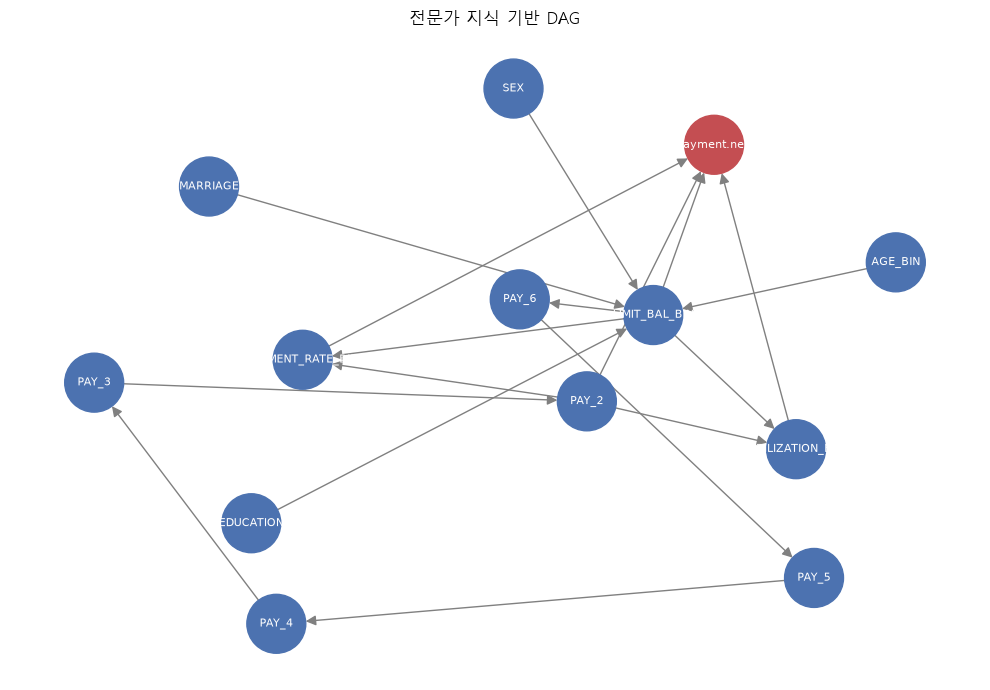

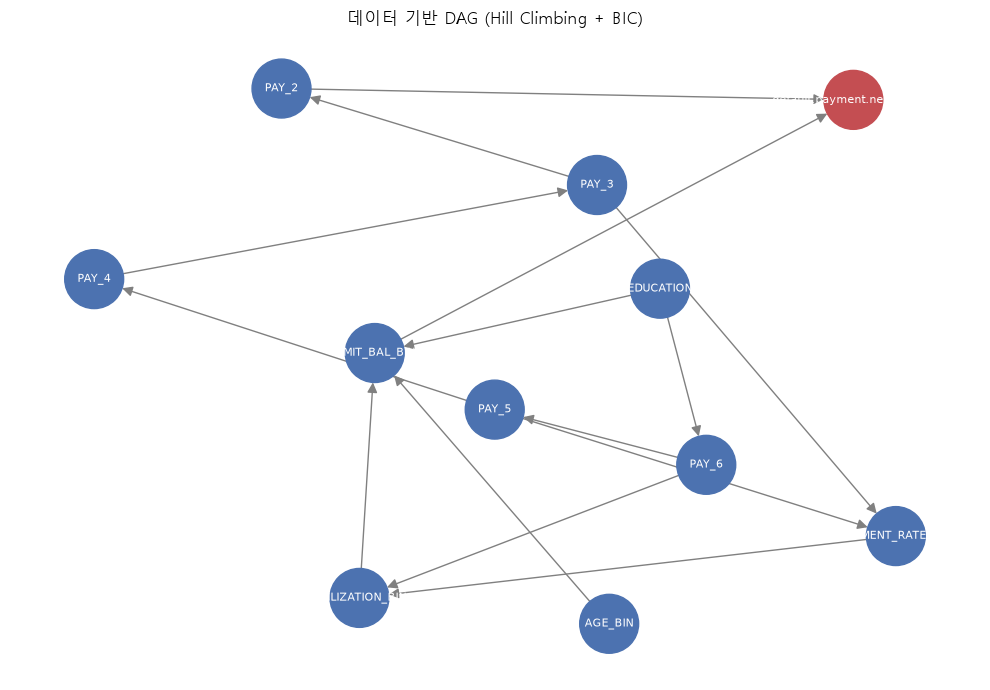

In [21]:
# ── 1) 전문가 구조 vs 학습 구조 간선 비교 ─────────────────────────
expert_set = set(expert_edges)
compare_df = pd.DataFrame({
    '간선 수': [len(expert_set), len(bic_edges), len(k2_edges)],
    '전문가 구조와 공통': [len(expert_set), len(expert_set & set(bic_edges)), len(expert_set & set(k2_edges))],
    '해당 구조에만 존재': [0, len(set(bic_edges) - expert_set), len(set(k2_edges) - expert_set)],
    '목표변수 부모 노드': [
        sorted(u for u, v in expert_edges if v == target),
        sorted(u for u, v in bic_edges if v == target),
        sorted(u for u, v in k2_edges if v == target)
    ]
}, index=['전문가', '학습(BIC)', '학습(K2)'])

print("=== 1) 구조 간 간선 비교 ===")
display(compare_df)

# ── 2) 학습 구조에서 추가된 간선 / 전문가 구조에서 누락된 간선 ────
for name, edges in [('BIC', bic_edges), ('K2', k2_edges)]:
    print(f"\n=== 2) {name}: 학습 구조에만 존재하는 간선 ===")
    print(sorted(set(edges) - expert_set))
    print(f"=== 3) {name}: 전문가 구조에만 존재하는 간선 ===")
    print(sorted(expert_set - set(edges)))

# ── 3) 구조 시각화 ────────────────────────────────────────────────
def draw_dag(edges, title):
    g = nx.DiGraph(edges)
    colors = ['#C44E52' if n == target else '#4C72B0' for n in g.nodes]
    plt.figure(figsize=(10, 7))
    nx.draw_networkx(g, pos=nx.spring_layout(g, seed=42, k=1.2), node_color=colors,
                     node_size=1800, font_size=8, font_color='white',
                     arrowsize=15, edge_color='gray')
    plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

draw_dag(expert_edges, '전문가 지식 기반 DAG')
draw_dag(bic_edges, '데이터 기반 DAG (Hill Climbing + BIC)')

### 3. 모델링

##### 3_1. 비교 모델 구조 정의 및 파라미터 학습

In [22]:
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator

In [24]:
# ── 1) K2 구조 재학습 (노드당 부모 수 제한) ───────────────────────
max_indeg = 3

def run_hc_limited(score, max_indegree):
    if 'expert_knowledge' in est_params:
        return hc.estimate(scoring_method=score, max_indegree=max_indegree,
                           expert_knowledge=ExpertKnowledge(forbidden_edges=black_list),
                           show_progress=False)
    return hc.estimate(scoring_method=score, max_indegree=max_indegree,
                       black_list=black_list, show_progress=False)

k2_dag = run_hc_limited(K2(train_main), max_indeg)
k2_edges = list(k2_dag.edges())

# ── 2) 재학습 구조 검증 ───────────────────────────────────────────
learned_check = pd.DataFrame([check_structure(bic_edges, '학습(BIC)'),
                              check_structure(k2_edges, f'학습(K2, 부모 수 ≤ {max_indeg})')])

print("=== 1) 학습 구조 검증 ===")
display(learned_check)

=== 1) 학습 구조 검증 ===


,구조,노드 수,간선 수,사이클 없음,시간 역행 간선 수,개인 특성 유입 간선 수,목표변수 자식 노드 수
0,학습(BIC),11,14,True,0,0,0
1,"학습(K2, 부모 수 ≤ 3)",11,23,True,0,0,0


In [25]:
# ── 1) 비교 모델 구조 정의 ────────────────────────────────────────
# - Naive Bayes: 목표변수 → 모든 입력 변수 (변수 간 독립 가정 기준선)
nb_features = [c for c in main_cols if c != target]

structures = {
    '전문가(PAYMENT_RATE)': expert_edges,
    '전문가(BALANCE_RATE)': expert_edges_balance,
    '학습(BIC)': bic_edges,
    '학습(K2)': k2_edges,
    'Naive Bayes': [(target, c) for c in nb_features]
}

# ── 2) 변수별 상태 목록 고정 (Train에 없는 상태 포함) ─────────────
state_names = {col: sorted(pd.concat([train_bn[col], test_bn[col]]).unique().tolist())
               for col in train_bn.columns}

# PAY_2 ~ PAY_6: 전체 데이터 기준 상태로 통일 (PAY_5, PAY_6의 값 1 포함)
all_pay_states = sorted(pd.unique(pd.concat([train_bn[pay_cols], test_bn[pay_cols]]).values.ravel()).tolist())
for col in pay_cols:
    state_names[col] = all_pay_states

# ── 3) 노드별 CPT 크기 계산 함수 (메모리 초과 사전 점검) ──────────
# - CPT 셀 수 = 노드 상태 수 × 부모 노드 상태 수의 곱
def max_cpt_cells(edges):
    g = nx.DiGraph(edges)
    sizes = []
    for node in g.nodes:
        parent_cards = [len(state_names[p]) for p in g.predecessors(node)]
        sizes.append(len(state_names[node]) * int(np.prod(parent_cards)))
    return max(sizes)

max_cells_limit = 5_000_000

# ── 4) 파라미터 추정 방식 정의 ────────────────────────────────────
# - MLE: 빈도 기반 최대우도 추정
# - Laplace: Dirichlet 사전분포 (pseudo_counts=1), 라플라스 평활
estimators = {
    'MLE': dict(cls=MaximumLikelihoodEstimator, kwargs={}),
    'Laplace': dict(cls=BayesianEstimator, kwargs=dict(prior_type='dirichlet', pseudo_counts=1))
}

# ── 5) CPT 학습 (Train 데이터만 사용) ─────────────────────────────
models = {}
rows = []

for s_name, edges in structures.items():
    cpt_cells = max_cpt_cells(edges)

    # CPT 크기가 한도를 넘는 구조는 학습에서 제외
    if cpt_cells > max_cells_limit:
        for e_name in estimators:
            rows.append({
                '구조': s_name, '추정 방식': e_name,
                '노드 수': len(set(sum(edges, ()))), '간선 수': len(edges),
                '최대 CPT 셀 수': cpt_cells,
                'CPT 자유 파라미터 수': None, '모델 유효성': '제외(CPT 과대)'
            })
        continue

    for e_name, e in estimators.items():
        model = BayesianNetwork(edges)
        cols = list(model.nodes())

        estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})
        model.add_cpds(*estimator.get_parameters(**e['kwargs']))
        models[(s_name, e_name)] = model

        try:
            valid = model.check_model()
        except Exception:
            valid = False

        free_params = sum(int(cpd.values.size / cpd.variable_card * (cpd.variable_card - 1))
                          for cpd in model.get_cpds())

        rows.append({
            '구조': s_name,
            '추정 방식': e_name,
            '노드 수': len(cols),
            '간선 수': len(edges),
            '최대 CPT 셀 수': cpt_cells,
            'CPT 자유 파라미터 수': free_params,
            '모델 유효성': valid
        })

# ── 6) 학습 결과 요약 ─────────────────────────────────────────────
print("=== 1) 모델별 CPT 학습 결과 ===")
display(pd.DataFrame(rows))

C:\Users\82102\AppData\Local\Temp\ipykernel_12868\2213232907.py:64: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})
C:\Users\82102\AppData\Local\Temp\ipykernel_12868\2213232907.py:64: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})
C:\Users\82102\AppData\Local\Temp\ipykernel_12868\2213232907.py:64: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})
C:\Users\82102

=== 1) 모델별 CPT 학습 결과 ===


C:\Users\82102\AppData\Local\Temp\ipykernel_12868\2213232907.py:64: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})
C:\Users\82102\AppData\Local\Temp\ipykernel_12868\2213232907.py:64: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = e['cls'](model, train_bn[cols], state_names={c: state_names[c] for c in cols})


,구조,추정 방식,노드 수,간선 수,최대 CPT 셀 수,CPT 자유 파라미터 수,모델 유효성
0,전문가(PAYMENT_RATE),MLE,13,17,1408,1745,True
1,전문가(PAYMENT_RATE),Laplace,13,17,1408,1745,True
2,전문가(BALANCE_RATE),MLE,13,17,1408,1745,True
3,전문가(BALANCE_RATE),Laplace,13,17,1408,1745,True
4,학습(BIC),MLE,11,14,484,1217,True
5,학습(BIC),Laplace,11,14,484,1217,True
6,학습(K2),MLE,11,23,14641,37737,True
7,학습(K2),Laplace,11,23,14641,37737,True
8,Naive Bayes,MLE,13,12,22,137,True
9,Naive Bayes,Laplace,13,12,22,137,True
